In [37]:
import torch
from torch.utils import data
from torch import nn
import matplotlib.pyplot as plt
batch_size=16
epoch=100
lr=0.01

In [38]:
def show_image(x, y):
    # 防止tensor位于GPU或带有计算图
    x = x.detach().cpu().flatten()
    y = y.detach().cpu().flatten()

    if len(x) != len(y):
        raise ValueError(
            f"x和y长度不同：{len(x)} != {len(y)}"
        )

    plt.figure(figsize=(10, 5))

    plt.plot(
        x.numpy(),
        y.numpy()
    )

    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid(True)
    plt.show()

In [39]:
def data_maker(tau):
    time=torch.arange(1000.0)
    x=torch.sin(0.01*time)+torch.normal(0,0.2,size=(1,1000))
    show_image(time,x)
    features=torch.zeros((1000-tau,tau))
    for i in range(tau):
        features[:,i]=x[0,i:1000-tau+i]
    labels=x[0,tau:].reshape(-1,1)
    return features,labels
    

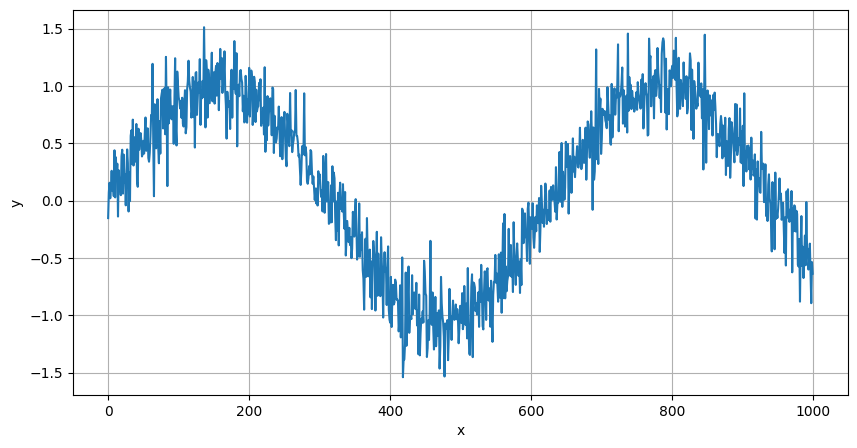

loss:0.05481
loss:0.05187
loss:0.05150
loss:0.05868
loss:0.05027
loss:0.05073
loss:0.05048
loss:0.05034
loss:0.05020
loss:0.05342
loss:0.05120
loss:0.05556
loss:0.05163
loss:0.05525
loss:0.05087
loss:0.05936
loss:0.04987
loss:0.05182
loss:0.05063
loss:0.05049
loss:0.05103
loss:0.05027
loss:0.05127
loss:0.05263
loss:0.04988
loss:0.05447
loss:0.05369
loss:0.05002
loss:0.05119
loss:0.05048
loss:0.05282
loss:0.05029
loss:0.04990
loss:0.05366
loss:0.05098
loss:0.05121
loss:0.05734
loss:0.05184
loss:0.05575
loss:0.05040
loss:0.05078
loss:0.05005
loss:0.05112
loss:0.05314
loss:0.05089
loss:0.05013
loss:0.05099
loss:0.05213
loss:0.05415
loss:0.05006
loss:0.06196
loss:0.05138
loss:0.05016
loss:0.05060
loss:0.05026
loss:0.05199
loss:0.05276
loss:0.05441
loss:0.05130
loss:0.05116
loss:0.05061
loss:0.05016
loss:0.05116
loss:0.05474
loss:0.05048
loss:0.05565
loss:0.05111
loss:0.05606
loss:0.05108
loss:0.05126
loss:0.05017
loss:0.05093
loss:0.05048
loss:0.05293
loss:0.05230
loss:0.05034
loss:0.05986

In [40]:
def data_loader(dataarry,batch_size,flag):
    dataset=data.TensorDataset(*(dataarry))
    return data.DataLoader(dataset,batch_size,shuffle=flag)
features,labels=data_maker(4)
train_iter=data_loader((features[:600,:],labels[:600,:]),batch_size,True)
test_iter=data_loader((features[600:,:],labels[600:,:]),batch_size,False)
net=nn.Sequential(nn.Linear(4,16),nn.ReLU(),nn.Linear(16,1))
loss=nn.MSELoss()
trainer=torch.optim.Adam(net.parameters(),lr=lr)
for i in range(epoch):
    net.train()
    for x,y in train_iter:
        trainer.zero_grad()
        l=loss(net(x),y)
        l.backward()
        trainer.step()
    net.eval()
    test_loss=0.0
    count=0
    with torch.no_grad():
        for x,y in test_iter:
            l=loss(net(x),y)
            test_loss+=l.item()*y.size(0)
            count+=y.size(0)
        print(f"loss:{test_loss/count:.5f}")
        



In [50]:
answer = []
answer.extend(
    labels.flatten().tolist()
)
predict=[]
for i in range(600):
    p=net(features[i,:])
    predict.append(p.item())
    # answer.append(labels[i,0].item())
for i in range(600,1000):
    if(i<604):
        cha=i-600
        ll=[]
        for j in range(4-cha,0,-1):
            ll.append(answer[600-j])
        for j in range(cha):
            ll.append(predict[j+600])
        x=torch.tensor(ll)
        predict.append(net(x).item())
    else:
        ll=[]
        for j in range(i-4,i):
            ll.append(predict[j])
        x=torch.tensor(ll)
        predict.append(net(x).item())
    # if(i<996):

    #     answer.append(labels[i,0].item())


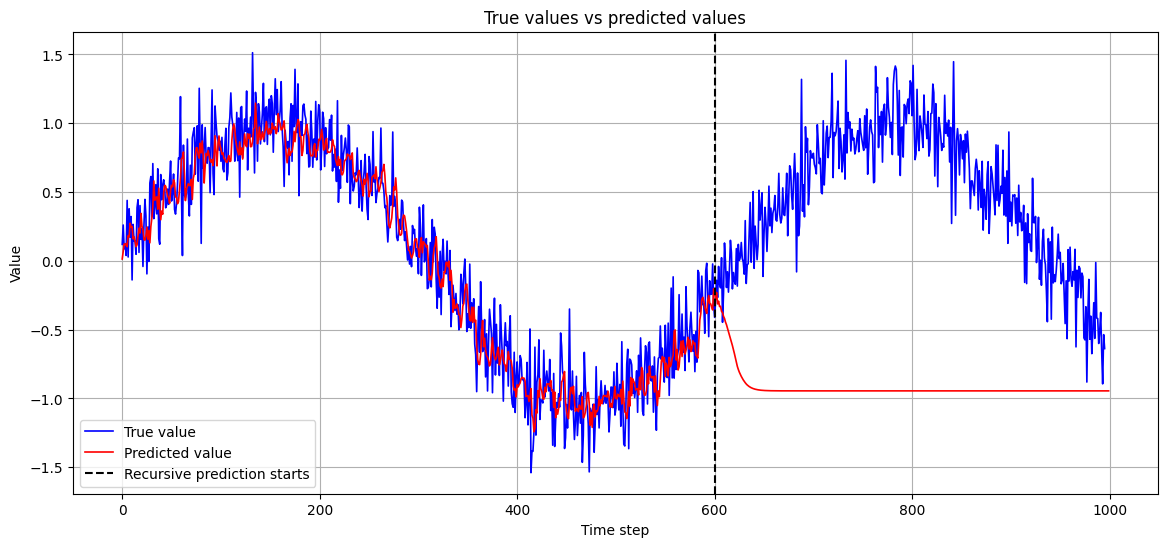

In [51]:
plt.figure(figsize=(14, 6))

# 真实值：共996个
plt.plot(
    range(len(answer)),
    answer,
    color="blue",
    linewidth=1.2,
    label="True value"
)

# 预测值：共1000个
plt.plot(
    range(len(predict)),
    predict,
    color="red",
    linewidth=1.2,
    label="Predicted value"
)

# 标记开始递归预测的位置
plt.axvline(
    x=600,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Recursive prediction starts"
)

plt.xlabel("Time step")
plt.ylabel("Value")
plt.title(
    "True values vs predicted values"
)

plt.legend()
plt.grid(True)
plt.show()